# DISCOVERING AI Agent

Q-learning maze adapted from https://www.geeksforgeeks.org/machine-learning/what-is-reinforcement-learning/ .

The maze, rewards and learning schedule follow the article. This notebook adds seed42, a 400-step safety limit, strict greedy evaluation and an independent BFS comparison. BFS is never used to train or modify Q. All code cells are self-contained. CPU NumPy is sufficient; this notebook is independent of the six-chapter V3 project.

## Khởi tạo và mê cung

In [1]:
import json, platform
from collections import deque
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
%matplotlib inline

plt.rcParams.update({"text.color": "black", "axes.labelcolor": "black",
                     "xtick.color": "black", "ytick.color": "black",
                     "font.size": 12, "figure.facecolor": "white"})
MAZE = np.array([
    [0, 1, 1, 1, 1, 1, 1, 1, 1, 1],
    [0, 0, 0, 0, 1, 0, 0, 0, 0, 1],
    [1, 1, 1, 0, 1, 0, 1, 1, 0, 1],
    [1, 0, 0, 0, 0, 0, 1, 0, 0, 1],
    [1, 0, 1, 1, 1, 1, 1, 0, 1, 1],
    [1, 0, 1, 0, 0, 0, 0, 0, 1, 1],
    [1, 0, 1, 0, 1, 1, 1, 0, 1, 1],
    [1, 0, 1, 0, 1, 0, 0, 0, 1, 1],
    [1, 0, 1, 0, 1, 0, 1, 0, 0, 1],
    [1, 1, 1, 0, 1, 1, 1, 1, 0, 0],
], dtype=np.int8)
START, GOAL = (0, 0), (9, 9)
ACTIONS = ((0, -1), (0, 1), (-1, 0), (1, 0))
print("Python:", platform.python_version(), "| NumPy:", np.__version__)
print("Maze:", MAZE.shape, "| Free cells:", int((MAZE == 0).sum()))
print("Start:", START, "| Goal:", GOAL, "| Q shape:", MAZE.shape + (4,))

Python: 3.11.17 | NumPy: 2.4.6
Maze: (10, 10) | Free cells: 43
Start: (0, 0) | Goal: (9, 9) | Q shape: (10, 10, 4)


## Môi trường và phản hồi

In [2]:
def valid(maze, state):
    row, col = state
    return bool(0 <= row < maze.shape[0] and 0 <= col < maze.shape[1] and maze[state] == 0)

def transition(maze, state, action, goal):
    delta = ACTIONS[action]
    following = (state[0] + delta[0], state[1] + delta[1])
    if not valid(maze, following):
        return state, -10, True
    if following == goal:
        return following, 50, True
    return following, -1, False
print("Down from start:", transition(MAZE, START, 3, GOAL))
print("Wall from start:", transition(MAZE, START, 1, GOAL))
print("Goal transition:", transition(MAZE, (9, 8), 1, GOAL))

Down from start: ((1, 0), -1, False)
Wall from start: ((0, 0), -10, True)
Goal transition: ((9, 9), 50, True)


## Chọn hành động và cập nhật Q

In [3]:
def choose_action(q, state, epsilon, rng):
    if not 0 <= epsilon <= 1:
        raise ValueError("epsilon must be between zero and one")
    if rng.random() < epsilon:
        return int(rng.integers(4))
    return int(np.argmax(q[state]))

def update_q(q, state, action, following, reward, done, alpha=0.1, gamma=0.9):
    future = 0.0 if done else float(np.max(q[following]))
    old = q[state + (action,)]
    q[state + (action,)] = old + alpha * (reward + gamma * future - old)
probe = np.zeros((10, 10, 4))
update_q(probe, (9, 8), 1, GOAL, 50, True)
print("Terminal update with alpha=0.1:", probe[9, 8, 1])
print("alpha=0.1 | gamma=0.9 | epsilon: 0.5 -> 0.01")

Terminal update with alpha=0.1: 5.0
alpha=0.1 | gamma=0.9 | epsilon: 0.5 -> 0.01


## Huấn luyện có seed và giới hạn bước

In [4]:
def train(maze=MAZE, start=START, goal=GOAL, episodes=5000, seed=42, max_steps=400):
    if episodes <= 0 or max_steps <= 0 or not valid(maze, start) or not valid(maze, goal):
        raise ValueError("Positive budgets and valid endpoints are required")
    rng = np.random.default_rng(seed)
    q = np.zeros(maze.shape + (4,), dtype=np.float64)
    epsilon = 0.5
    returns, lengths, successes = [], [], []
    truncated = 0
    for _ in range(episodes):
        state, total, reached = start, 0, False
        for step in range(1, max_steps + 1):
            action = choose_action(q, state, epsilon, rng)
            following, reward, done = transition(maze, state, action, goal)
            update_q(q, state, action, following, reward, done)
            state, total = following, total + reward
            if done:
                reached = state == goal
                break
        else:
            truncated += 1
        returns.append(total)
        lengths.append(step)
        successes.append(reached)
        epsilon = max(0.01, epsilon * 0.995)
    return {"q": q, "returns": np.array(returns), "lengths": np.array(lengths),
            "successes": np.array(successes), "truncated": truncated, "epsilon": epsilon}
result = train(episodes=5000, seed=42, max_steps=400)
Q = result["q"]
for left in (0, 1000, 4000):
    right = left + 1000
    success = result["successes"][left:right].mean()
    mean_return = result["returns"][left:right].mean()
    print(f"Episodes {left+1:4d}-{right}: success={success:.1%}, return={mean_return:.2f}")
print("Final epsilon:", result["epsilon"], "| Truncated:", result["truncated"])

Episodes    1-1000: success=25.0%, return=-10.59
Episodes 1001-2000: success=87.0%, return=20.65
Episodes 4001-5000: success=87.6%, return=20.95
Final epsilon: 0.01 | Truncated: 0


## Đánh giá chính sách greedy

In [5]:
def greedy_path(maze, q, start, goal, max_steps=200):
    path, visited = [start], {start}
    for _ in range(max_steps):
        if path[-1] == goal:
            return path, "goal"
        following, _, done = transition(maze, path[-1], int(np.argmax(q[path[-1]])), goal)
        if done and following != goal:
            return path, "collision"
        if following in visited:
            return path, "loop"
        path.append(following)
        visited.add(following)
    return path, "goal" if path[-1] == goal else "step_limit"
path, status = greedy_path(MAZE, Q, START, GOAL)
print("Greedy status:", status, "| Moves:", len(path) - 1)
print("Learned route:", path)

Greedy status: goal | Moves: 24
Learned route: [(0, 0), (1, 0), (1, 1), (1, 2), (1, 3), (2, 3), (3, 3), (3, 4), (3, 5), (2, 5), (1, 5), (1, 6), (1, 7), (1, 8), (2, 8), (3, 8), (3, 7), (4, 7), (5, 7), (6, 7), (7, 7), (8, 7), (8, 8), (9, 8), (9, 9)]


## BFS chỉ làm đối chứng sau huấn luyện

In [6]:
def shortest_path(maze, start, goal):
    pending, parent = deque([start]), {start: None}
    while pending:
        state = pending.popleft()
        if state == goal:
            path = []
            while state is not None:
                path.append(state)
                state = parent[state]
            return path[::-1]
        for delta in ACTIONS:
            following = (state[0] + delta[0], state[1] + delta[1])
            if valid(maze, following) and following not in parent:
                parent[following] = state
                pending.append(following)
    return []

def valid_path(maze, path):
    if not path or not all(valid(maze, state) for state in path):
        return False
    return all(abs(a[0] - b[0]) + abs(a[1] - b[1]) == 1 for a, b in zip(path, path[1:]))
reference = shortest_path(MAZE, START, GOAL)
assert status == "goal" and valid_path(MAZE, path)
assert len(path) == len(reference)
print("BFS minimum moves:", len(reference) - 1)
print("Valid route:", valid_path(MAZE, path), "| Same length:", len(path) == len(reference))
print("Greedy undiscounted return:", 50 - (len(path) - 2))

BFS minimum moves: 24
Valid route: True | Same length: True
Greedy undiscounted return: 27


## Đường đi học được

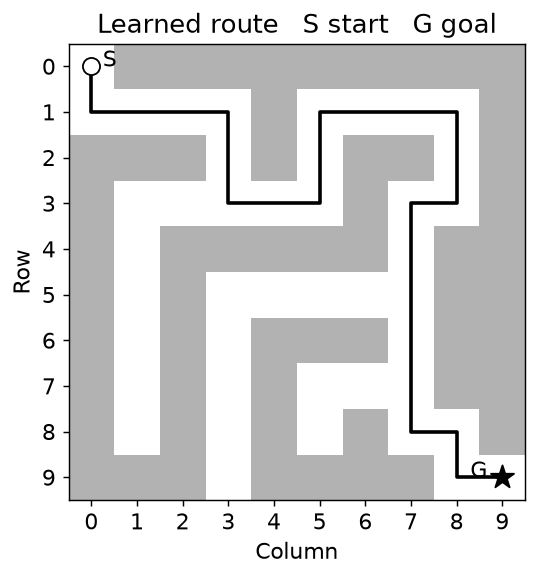

In [7]:
fig, ax = plt.subplots(figsize=(5, 4.6), dpi=130)
ax.imshow(MAZE, cmap=ListedColormap(["white", "0.7"]), vmin=0, vmax=1)
rows, columns = zip(*path)
ax.plot(columns, rows, color="black", linewidth=2)
ax.scatter(START[1], START[0], marker="o", s=90,
           facecolors="white", edgecolors="black", zorder=4)
ax.scatter(GOAL[1], GOAL[0], marker="*", s=180, color="black", zorder=4)
ax.set(xticks=range(10), yticks=range(10), xlabel="Column", ylabel="Row")
ax.set_title("Learned route   S start   G goal")
ax.text(START[1]+0.25, START[0], "S", color="black")
ax.text(GOAL[1]-0.7, GOAL[0], "G", color="black")
fig.tight_layout()
plt.show()

## Phần thưởng trong quá trình học

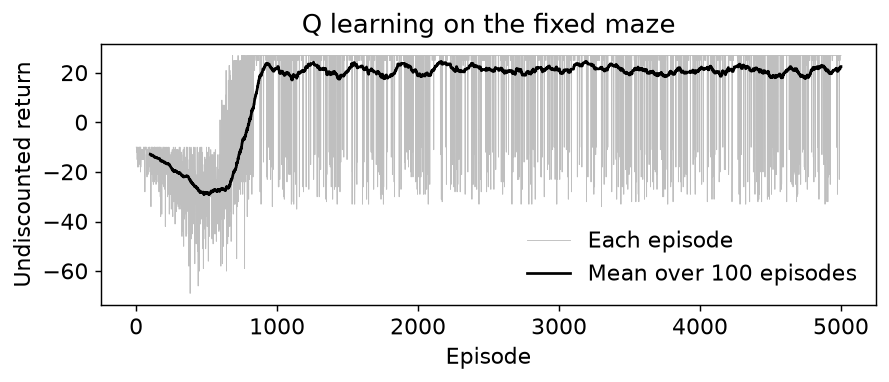

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.1), dpi=130)
returns = result["returns"]
ax.plot(np.arange(1, 5001), returns, color="0.75", linewidth=0.5,
        label="Each episode")
rolling = np.convolve(returns, np.ones(100)/100, mode="valid")
ax.plot(np.arange(100, 5001), rolling, color="black", linewidth=1.5,
        label="Mean over 100 episodes")
ax.set(xlabel="Episode", ylabel="Undiscounted return",
       title="Q learning on the fixed maze")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

## Kết quả kiểm chứng

In [9]:
summary = {
    "seed": 42, "episodes": 5000, "q_shape": list(Q.shape),
    "free_cells": int((MAZE == 0).sum()), "greedy_status": status,
    "learned_moves": len(path)-1, "bfs_moves": len(reference)-1,
    "valid_route": valid_path(MAZE, path),
    "greedy_return": 50-(len(path)-2),
    "last_1000_success_rate": float(result["successes"][-1000:].mean()),
    "last_1000_mean_return": float(result["returns"][-1000:].mean()),
    "truncated_episodes": int(result["truncated"]),
    "execution_device": "CPU NumPy", "path": path,
}
print(json.dumps(summary))

{"seed": 42, "episodes": 5000, "q_shape": [10, 10, 4], "free_cells": 43, "greedy_status": "goal", "learned_moves": 24, "bfs_moves": 24, "valid_route": true, "greedy_return": 27, "last_1000_success_rate": 0.876, "last_1000_mean_return": 20.951, "truncated_episodes": 0, "execution_device": "CPU NumPy", "path": [[0, 0], [1, 0], [1, 1], [1, 2], [1, 3], [2, 3], [3, 3], [3, 4], [3, 5], [2, 5], [1, 5], [1, 6], [1, 7], [1, 8], [2, 8], [3, 8], [3, 7], [4, 7], [5, 7], [6, 7], [7, 7], [8, 7], [8, 8], [9, 8], [9, 9]]}
